# Modularity on the Karate Club Graph
**DSC212: Graph Theory — Research Assignment**

**Name:** Vigneswara
**Roll no:** IMS25226

This notebook implements **recursive spectral modularity bisection** from scratch (NumPy + NetworkX only) on Zachary's Karate Club network, visualises every split, tracks four node metrics across iterations, and discusses the results.

Method reference: M. E. J. Newman (2006), *Modularity and community structure in networks*, PNAS 103(23):8577–8582.

**Conventions.** NetworkX labels the members 0–33 (Zachary's paper uses 1–34). Node 0 is the instructor "Mr. Hi", node 33 is the administrator ("Officer"/president).

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm

plt.rcParams["figure.dpi"] = 110
np.set_printoptions(precision=3, suppress=True)

G = nx.karate_club_graph()
nodes = list(G.nodes())            # 0..33
n, m = G.number_of_nodes(), G.number_of_edges()
print(f"n = {n} nodes, m = {m} edges")

n = 34 nodes, m = 78 edges


## 1. Modularity matrix
$B = A - \frac{k k^\top}{2m}$, and the modularity of a labelling is $Q = \frac{1}{4m}s^\top B s$.
We also verify Propositions 1 and 2 numerically (B symmetric, $B\mathbf 1 = 0$).

In [2]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)     # unweighted adjacency matrix (karate graph in recent NetworkX carries edge weights; the assignment uses A in {0,1})
k = A.sum(axis=1)                            # degree vector
B = A - np.outer(k, k) / (2 * m)             # global modularity matrix

print("B symmetric          :", np.allclose(B, B.T))
print("B @ 1 == 0           :", np.allclose(B @ np.ones(n), 0))
print("sum of degrees == 2m :", k.sum() == 2 * m)
print("eigenvalues of B (top 5):", np.sort(np.linalg.eigvalsh(B))[::-1][:5])

B symmetric          : True
B @ 1 == 0           : True
sum of degrees == 2m : True
eigenvalues of B (top 5): [4.977 3.043 2.32  1.489 1.459]


## 2. Core routines
* `leading_eigenpair(B_C)` – uses `numpy.linalg.eigh` (for real symmetric matrices; eigenvalues returned ascending, so the leading pair is the last one).
* `bisect(C)` – restrict $B$ to the community $C$ (the block $B^{(C)}$), compute the leading eigenpair, stop if $\lambda_1 \le 0$ (Theorem 3), otherwise split by the **sign** of $u_1$ (entries $>0$ → $+1$, otherwise $-1$).
* `modularity(partition)` – total $Q$ of a multi-community partition, $Q=\frac{1}{2m}\sum_{ij}B_{ij}\,\delta(c_i,c_j)$ (for two groups this equals $\frac1{4m}s^\top B s$ + the constant $0$ from $\mathbf 1^\top B\mathbf 1=0$).

In [3]:
TOL = 1e-9   # numerical zero for the eigenvalue test

def leading_eigenpair(B_C):
    # eigh: real symmetric -> real eigenvalues (ascending), orthonormal eigenvectors
    vals, vecs = np.linalg.eigh(B_C)
    return vals[-1], vecs[:, -1]

def bisect(C):
    # Try to split community C (list of node ids). Returns (lam1, C_plus, C_minus) or (lam1, None, None).
    C = list(C)
    B_C = B[np.ix_(C, C)]                      # restricted modularity matrix B^(C)
    lam1, u1 = leading_eigenpair(B_C)
    if lam1 <= TOL:                            # Theorem 3: no split can increase modularity
        return lam1, None, None
    s = np.where(u1 > 0, 1, -1)                # threshold back to {-1,+1}
    C_plus  = [C[i] for i in range(len(C)) if s[i] ==  1]
    C_minus = [C[i] for i in range(len(C)) if s[i] == -1]
    if len(C_plus) == 0 or len(C_minus) == 0:  # degenerate split -> treat as indivisible
        return lam1, None, None
    return lam1, C_plus, C_minus

def modularity(partition):
    # Q = (1/2m) * sum over communities of 1^T B^(C) 1
    return sum(B[np.ix_(C, C)].sum() for C in partition) / (2 * m)

## 3. Recursive bisection
We keep a queue of communities still to be tested. **One iteration = one successful split**; after each one we snapshot the whole partition. Iteration 0 is the unsplit graph (a single community, $Q=0$).

In [4]:
def recursive_bisection(nodes):
    partition = [sorted(nodes)]
    history = [dict(iteration=0, partition=[list(c) for c in partition], Q=modularity(partition),
                    split=None, lam1=None)]
    queue = [sorted(nodes)]
    final = []
    it = 0
    while queue:
        C = queue.pop(0)
        lam1, Cp, Cm = bisect(C)
        if Cp is None:
            final.append(C)
            why = "lambda1 <= 0" if lam1 <= TOL else "leading eigenvector has a single sign (no non-trivial split)"
            print(f"  community of size {len(C):2d}: lambda1 = {lam1:+.4f}; {why} -> indivisible")
            continue
        it += 1
        partition.remove(C)
        partition += [Cp, Cm]
        queue += [Cp, Cm]
        history.append(dict(iteration=it, partition=[list(c) for c in partition],
                            Q=modularity(partition), split=(C, Cp, Cm), lam1=lam1))
        print(f"iteration {it}: split size {len(C)} (lambda1 = {lam1:.4f}) -> sizes {len(Cp)} + {len(Cm)};  Q = {history[-1]['Q']:.4f}")
    return history, final

history, final_communities = recursive_bisection(nodes)
print("\nFinal communities:")
for i, c in enumerate(sorted(final_communities, key=lambda c: min(c))):
    print(f"  C{i}: {sorted(c)}")
print(f"\nFinal modularity Q = {modularity(final_communities):.4f}")

iteration 1: split size 34 (lambda1 = 4.9771) -> sizes 16 + 18;  Q = 0.3715
iteration 2: split size 16 (lambda1 = 2.9441) -> sizes 10 + 6;  Q = 0.3898
iteration 3: split size 18 (lambda1 = 2.5041) -> sizes 5 + 13;  Q = 0.4081
  community of size 10: lambda1 = +2.5712; leading eigenvector has a single sign (no non-trivial split) -> indivisible
iteration 4: split size 6 (lambda1 = 2.1480) -> sizes 1 + 5;  Q = 0.4094
  community of size  5: lambda1 = +1.8759; leading eigenvector has a single sign (no non-trivial split) -> indivisible
  community of size 13: lambda1 = +2.3563; leading eigenvector has a single sign (no non-trivial split) -> indivisible
  community of size  1: lambda1 = -0.0064; lambda1 <= 0 -> indivisible
  community of size  5: lambda1 = +2.1470; leading eigenvector has a single sign (no non-trivial split) -> indivisible

Final communities:
  C0: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  C1: [4, 5, 6, 10, 16]
  C2: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  C3: [11]


### Sanity check against NetworkX's modularity and the real-life split
`nx.community.modularity` is used **only to verify** our own Q. The ground truth is the `club` attribute (Mr. Hi vs. Officer) recorded by Zachary.

In [5]:
from networkx.algorithms.community import modularity as nx_modularity
for h in history:
    q_nx = nx_modularity(G, [set(c) for c in h["partition"]], weight=None)
    assert abs(q_nx - h["Q"]) < 1e-9, (h["iteration"], q_nx, h["Q"])
print("Our Q matches networkx.modularity at every iteration.")

# --- first split vs. the real split ---
truth = {v: G.nodes[v]["club"] for v in nodes}
first = history[1]["split"]
for name, grp in [("group +", first[1]), ("group -", first[2])]:
    hi = sum(truth[v] == "Mr. Hi" for v in grp)
    print(f"{name}: size {len(grp)},  Mr. Hi members = {hi},  Officer members = {len(grp)-hi}")

g0 = set(first[1]) if 0 in first[1] else set(first[2])      # side containing Mr. Hi (node 0)
mis = [v for v in nodes if (v in g0) != (truth[v] == "Mr. Hi")]
print(f"\nFirst split reproduces the real fission for {n-len(mis)}/{n} members ({(n-len(mis))/n:.1%}).")
print("Misclassified node(s):", mis)

Our Q matches networkx.modularity at every iteration.
group +: size 16,  Mr. Hi members = 16,  Officer members = 0
group -: size 18,  Mr. Hi members = 1,  Officer members = 17

First split reproduces the real fission for 33/34 members (97.1%).
Misclassified node(s): [8]


## 3b. Remark: handout's block $B^{(C)}$ vs. Newman's generalized $B^{(g)}$
The handout restricts $B$ to $C$ and tests $\lambda_1^{(C)}>0$. In Newman (2006, Eq. 6) the *exact* modularity gain of splitting $g$ uses the generalized matrix
$B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in g}B_{il}$, whose rows sum to zero (so $\mathbf 1$ is again an eigenvector with eigenvalue 0 and $\lambda_1\ge 0$ always). With the plain block, a community can have $\lambda_1>0$ yet a leading eigenvector of one sign, so no split results (seen above for the groups of size 10, 5, 13, 5). Below we rerun the recursion with $B^{(g)}$ for comparison; **the main results of this notebook follow the handout (plain block).**

In [6]:
def bisect_generalized(C):
    C = list(C)
    B_C = B[np.ix_(C, C)]
    B_g = B_C - np.diag(B_C.sum(axis=1))             # Newman's correction
    lam1, u1 = leading_eigenpair(B_g)
    if lam1 <= TOL: return lam1, None, None
    s = np.where(u1 > 0, 1, -1)
    dQ = s @ B_g @ s / (4 * m)                       # exact modularity gain
    if dQ <= TOL or abs(s.sum()) == len(s): return lam1, None, None
    return lam1, [C[i] for i in range(len(C)) if s[i] == 1], [C[i] for i in range(len(C)) if s[i] == -1]

def run(bisect_fn):
    queue, final = [sorted(nodes)], []
    while queue:
        C = queue.pop(0); _, Cp, Cm = bisect_fn(C)
        if Cp is None: final.append(C)
        else: queue += [Cp, Cm]
    return sorted(final, key=min)

alt = run(bisect_generalized)
print("Generalized B^(g): %d communities, Q = %.4f" % (len(alt), modularity(alt)))
for c in alt: print("  ", c)
print("Handout block B^(C): %d communities, Q = %.4f" % (len(final_communities), modularity(final_communities)))
print("Reference (networkx greedy modularity):",
      round(nx_modularity(G, nx.community.greedy_modularity_communities(G, weight=None), weight=None), 4))

Generalized B^(g): 4 communities, Q = 0.3934
   [0, 4, 5, 6, 10, 11, 16]
   [1, 2, 3, 7, 12, 13, 17, 19, 21]
   [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
   [23, 24, 25, 27, 28, 31]
Handout block B^(C): 5 communities, Q = 0.4094
Reference (networkx greedy modularity): 0.3807


## 4. Visualisation after each split
A **fixed spring layout** (`seed=42`) is computed once and reused so that only the colours change. Every community gets a unique colour; nodes are labelled by ID.

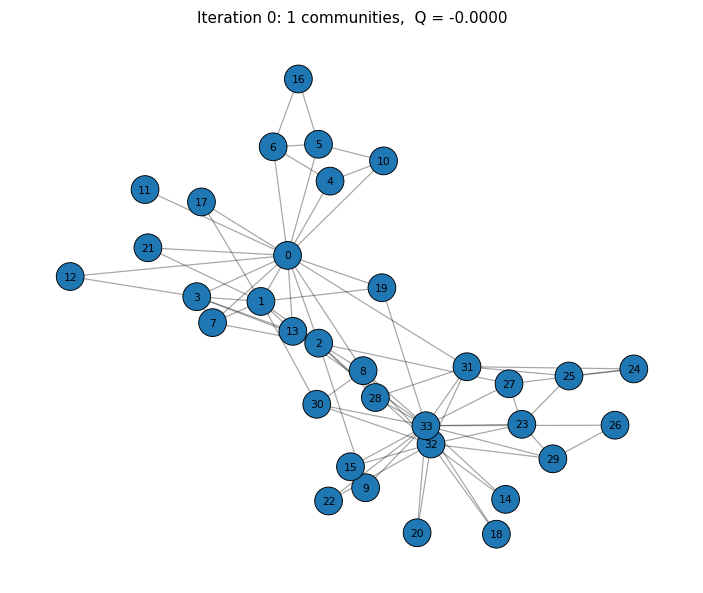

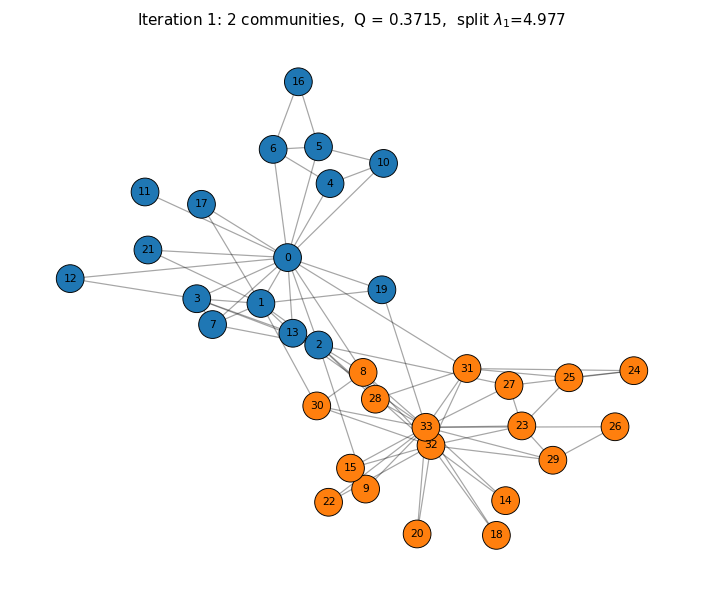

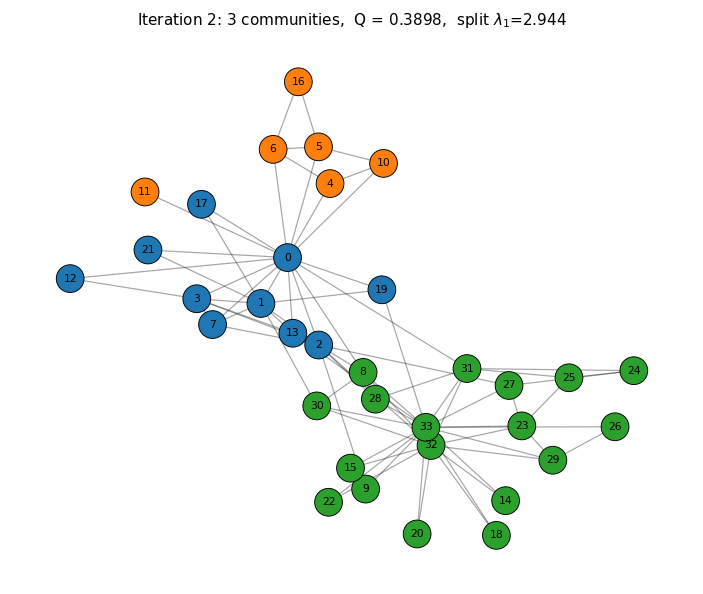

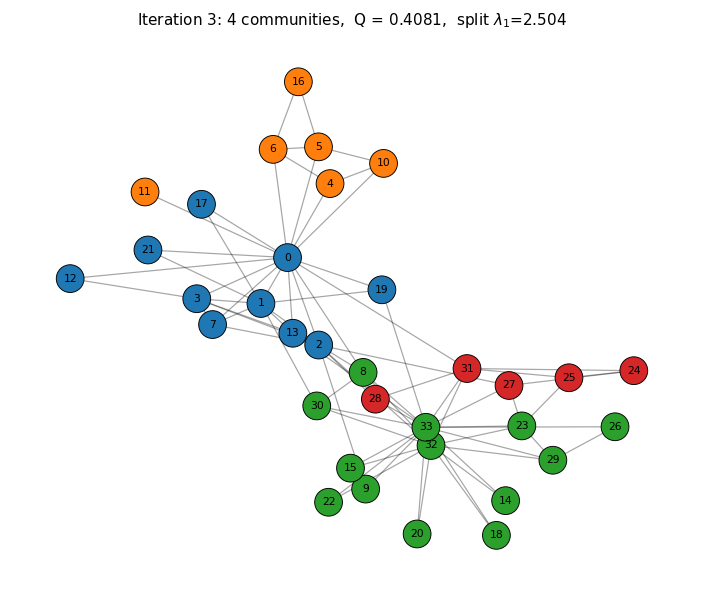

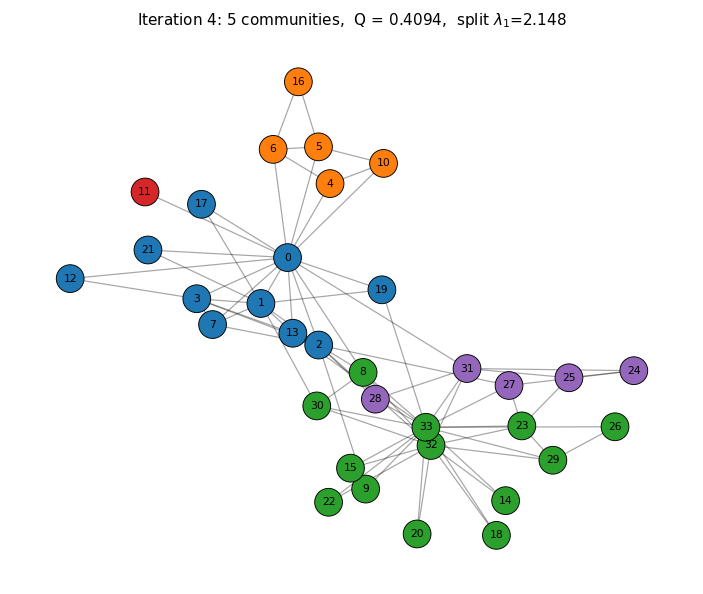

In [7]:
pos = nx.spring_layout(G, seed=42)
palette = plt.get_cmap("tab10")

def draw_partition(ax, partition, title):
    colour = {}
    for ci, C in enumerate(sorted(partition, key=lambda c: min(c))):
        for v in C:
            colour[v] = palette(ci % 10)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=0.8)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[colour[v] for v in nodes],
                           node_size=330, edgecolors="black", linewidths=0.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10); ax.axis("off")

for h in history:
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    lam = "" if h["lam1"] is None else f",  split $\\lambda_1$={h['lam1']:.3f}"
    draw_partition(ax, h["partition"], f"Iteration {h['iteration']}: {len(h['partition'])} communities,  Q = {h['Q']:.4f}{lam}")
    plt.tight_layout(); plt.show()

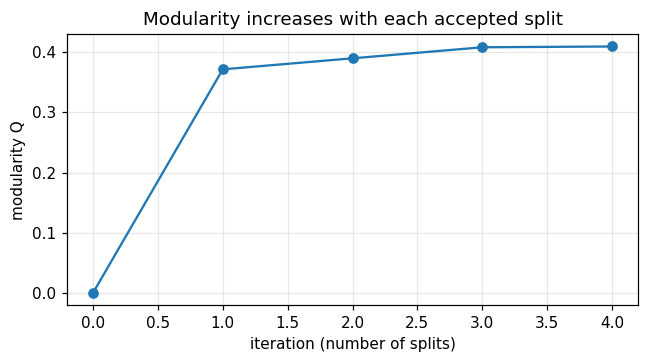

In [8]:
# Modularity vs. iteration
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot([h["iteration"] for h in history], [h["Q"] for h in history], "o-")
ax.set_xlabel("iteration (number of splits)"); ax.set_ylabel("modularity Q")
ax.set_title("Modularity increases with each accepted split"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Node metrics after each split
After iteration $t$ every node lies in a community. To make the metrics respond to the community structure we compute them on the **induced subgraph of the node's own community** (`G.subgraph(C)`), using the NetworkX functions `degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`. Iteration 0 is the whole graph, so it equals the usual global values.

*Note:* inside a community, centralities are normalised by that community's size, so they describe a node's importance **within its group**. A singleton community has all metrics $=0$.

In [9]:
metric_funcs = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

metrics = {name: {} for name in metric_funcs}          # metrics[name][iteration] = {node: value}
for h in history:
    for name, f in metric_funcs.items():
        vals = {}
        for C in h["partition"]:
            if len(C) == 1:                      # metrics are undefined for a singleton -> set to 0
                vals[C[0]] = 0.0
                continue
            vals.update(f(G.subgraph(C)))
        metrics[name][h["iteration"]] = vals

iters = [h["iteration"] for h in history]
import pandas as pd
tables = {name: pd.DataFrame({it: metrics[name][it] for it in iters}).sort_index() for name in metrics}
for name, df in tables.items():
    print(f"\n{name} - top 5 nodes at iteration 0 and at the final iteration")
    print("  iter 0 :", dict(df[0].nlargest(5).round(3)))
    print(f"  iter {iters[-1]} :", dict(df[iters[-1]].nlargest(5).round(3)))


Degree centrality - top 5 nodes at iteration 0 and at the final iteration
  iter 0 : {33: np.float64(0.515), 0: np.float64(0.485), 32: np.float64(0.364), 2: np.float64(0.303), 1: np.float64(0.273)}
  iter 4 : {0: np.float64(1.0), 33: np.float64(1.0), 1: np.float64(0.889), 32: np.float64(0.833), 5: np.float64(0.75)}

Betweenness centrality - top 5 nodes at iteration 0 and at the final iteration
  iter 0 : {0: np.float64(0.438), 33: np.float64(0.304), 32: np.float64(0.145), 2: np.float64(0.144), 31: np.float64(0.138)}
  iter 4 : {33: np.float64(0.545), 24: np.float64(0.5), 31: np.float64(0.5), 0: np.float64(0.354), 32: np.float64(0.258)}

Closeness centrality - top 5 nodes at iteration 0 and at the final iteration
  iter 0 : {0: np.float64(0.569), 2: np.float64(0.559), 33: np.float64(0.55), 31: np.float64(0.541), 8: np.float64(0.516)}
  iter 4 : {0: np.float64(1.0), 33: np.float64(1.0), 1: np.float64(0.9), 32: np.float64(0.857), 5: np.float64(0.8)}

Clustering coefficient - top 5 nodes 

## 6. Evolution of each metric
For each metric: (left) a line plot of all 34 nodes across iterations, with the nodes that are top-5 at *any* iteration highlighted and labelled, the rest in grey; (right) a heatmap of every node × iteration.

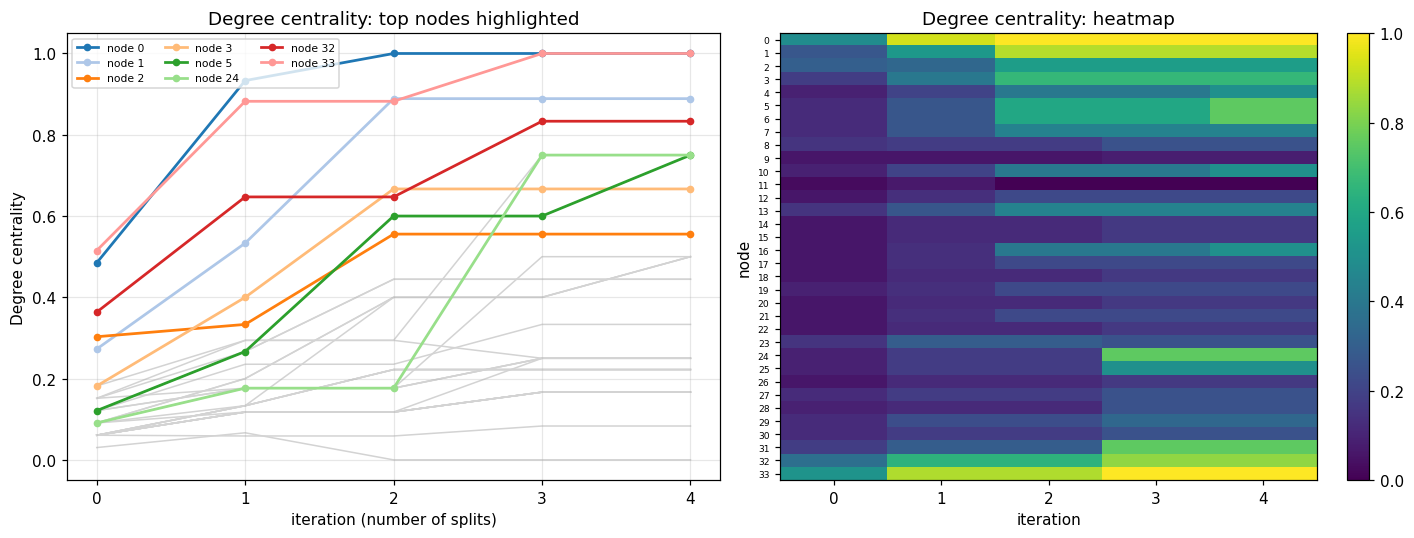

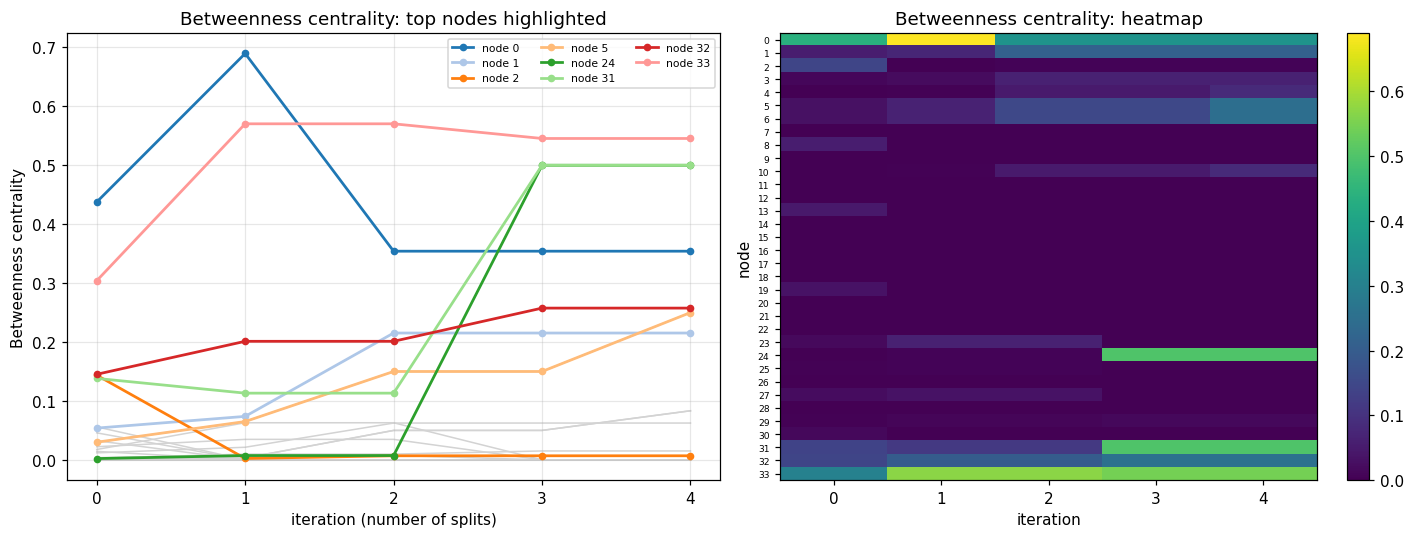

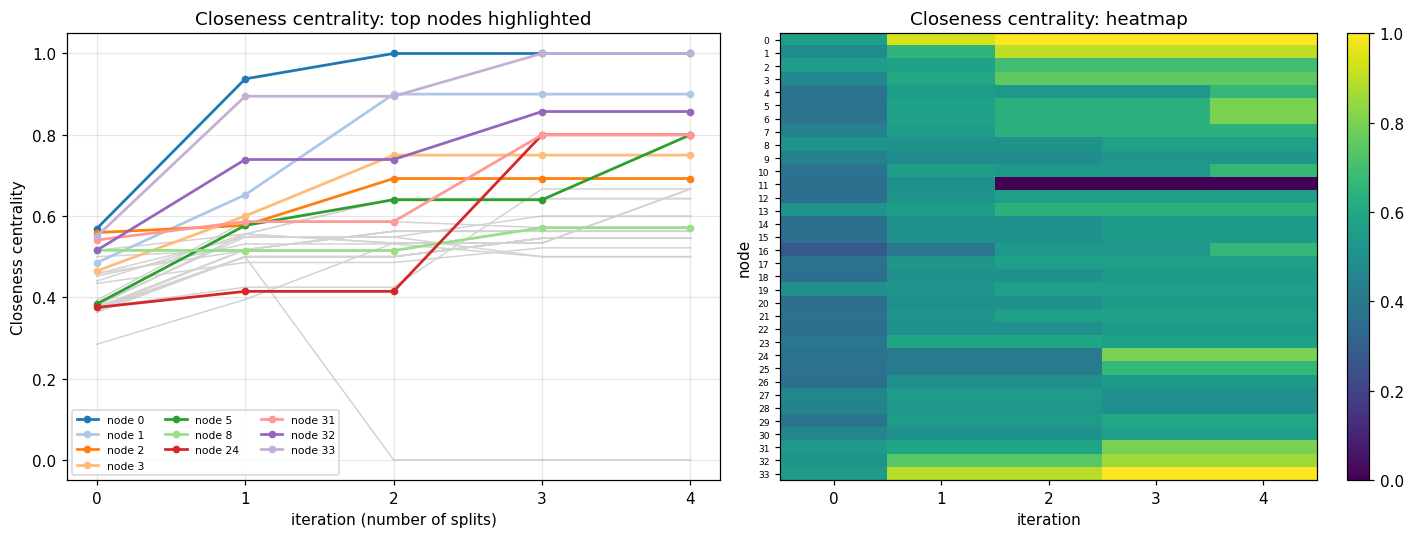

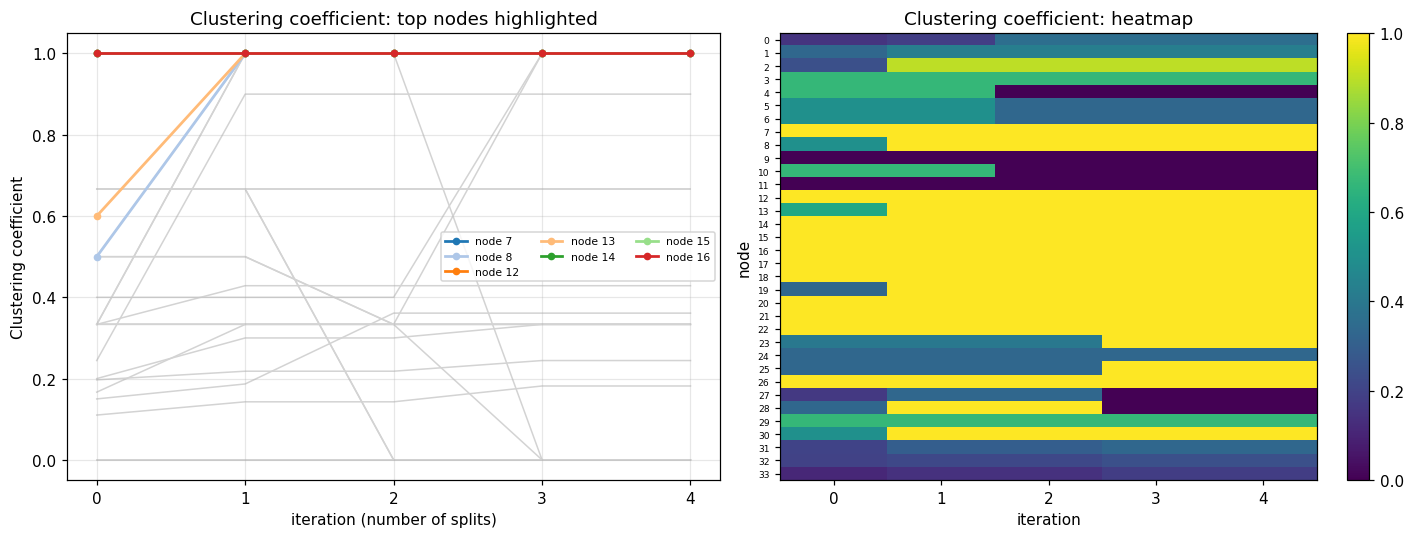

In [10]:
def plot_metric(name):
    df = tables[name]
    top = set()
    for it in iters:
        top |= set(df[it].nlargest(5).index)
    top = sorted(top)
    colors = {v: plt.get_cmap("tab20")(i % 20) for i, v in enumerate(top)}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.1, 1]})
    for v in nodes:
        if v not in top:
            ax1.plot(iters, df.loc[v], color="lightgrey", lw=1, zorder=1)
    for v in top:
        ax1.plot(iters, df.loc[v], marker="o", ms=4, lw=1.8, color=colors[v], label=f"node {v}", zorder=2)
    ax1.set_xticks(iters); ax1.set_xlabel("iteration (number of splits)"); ax1.set_ylabel(name)
    ax1.set_title(f"{name}: top nodes highlighted"); ax1.grid(alpha=.3)
    ax1.legend(ncol=3, fontsize=7)

    im = ax2.imshow(df.values, aspect="auto", cmap="viridis")
    ax2.set_xticks(range(len(iters))); ax2.set_xticklabels(iters)
    ax2.set_yticks(range(n)); ax2.set_yticklabels(df.index, fontsize=6)
    ax2.set_xlabel("iteration"); ax2.set_ylabel("node"); ax2.set_title(f"{name}: heatmap")
    fig.colorbar(im, ax=ax2, fraction=0.046)
    plt.tight_layout(); plt.show()

for name in metrics:
    plot_metric(name)

### Bar plot of the final state vs. the start

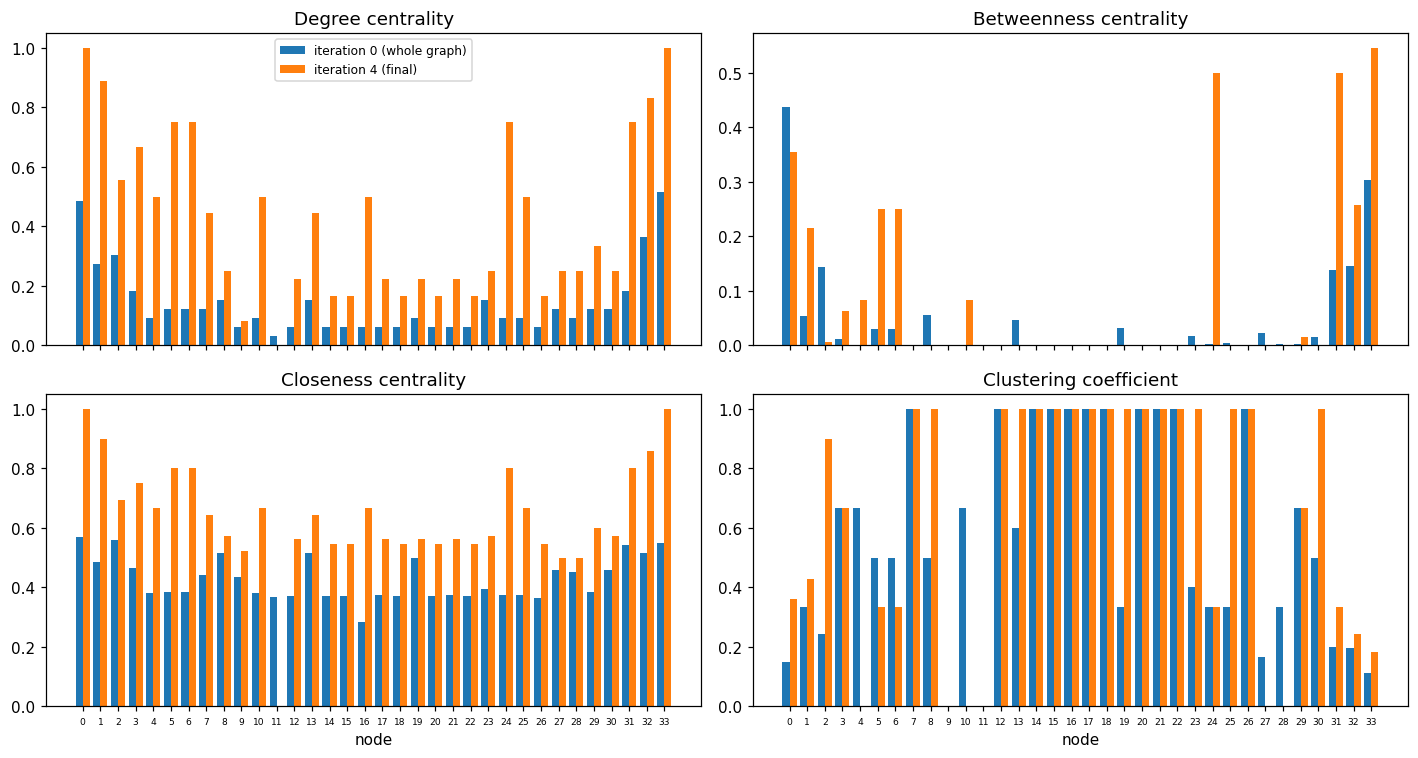

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
w = 0.4
for ax, name in zip(axes.ravel(), metrics):
    df = tables[name]
    ax.bar(np.arange(n) - w/2, df[0].values, w, label="iteration 0 (whole graph)")
    ax.bar(np.arange(n) + w/2, df[iters[-1]].values, w, label=f"iteration {iters[-1]} (final)")
    ax.set_title(name); ax.set_xticks(range(n)); ax.set_xticklabels(range(n), fontsize=6)
axes[0,0].legend(fontsize=8)
for ax in axes[1]: ax.set_xlabel("node")
plt.tight_layout(); plt.show()

## 7. Quantifying "consistently central" nodes
Mean **rank** of each node (1 = most central) across all iterations, per metric, plus how many iterations it is in the top 5.

In [12]:
rank_tables = {name: tables[name].rank(ascending=False, method="min") for name in metrics}
summary = pd.DataFrame({
    f"{name.split()[0]} mean rank": rank_tables[name].mean(axis=1) for name in metrics
})
summary["overall mean rank"] = summary.mean(axis=1)
summary["top-5 count (all metrics)"] = sum((rank_tables[name] <= 5).sum(axis=1) for name in metrics)
summary["community (final)"] = {v: ci for ci, C in enumerate(sorted(final_communities, key=lambda c: min(c))) for v in C}
print(summary.sort_values("overall mean rank").head(10).round(2).to_string())

# degree-vs-betweenness gap: who is a "broker" at the start
df_b0 = tables["Betweenness centrality"][0]; df_d0 = tables["Degree centrality"][0]
print("\nGlobal (iteration 0) top-5 betweenness:", dict(df_b0.nlargest(5).round(3)))
print("Global (iteration 0) top-5 degree      :", dict(df_d0.nlargest(5).round(3)))

    Degree mean rank  Betweenness mean rank  Closeness mean rank  Clustering mean rank  overall mean rank  top-5 count (all metrics)  community (final)
0                1.2                    2.4                  1.0                  25.6               7.55                         15                  0
1                3.4                    5.8                  4.2                  21.6               8.75                         11                  0
33               1.6                    1.4                  2.0                  30.0               8.75                         15                  2
13              10.6                   14.0                  9.6                   4.0               9.55                          5                  0
32               3.8                    4.0                  4.2                  28.4              10.10                         15                  2
7               11.2                   17.0                 11.4                   1.0  

In [13]:
# Evolution of the key nodes' metrics (numbers used in the discussion below)
key = [0, 33, 32, 2, 1, 31, 7, 13]
for name in metrics:
    print(name); print(tables[name].loc[key].round(2).to_string()); print()

Degree centrality
       0     1     2     3     4
0   0.48  0.93  1.00  1.00  1.00
33  0.52  0.88  0.88  1.00  1.00
32  0.36  0.65  0.65  0.83  0.83
2   0.30  0.33  0.56  0.56  0.56
1   0.27  0.53  0.89  0.89  0.89
31  0.18  0.29  0.29  0.75  0.75
7   0.12  0.27  0.44  0.44  0.44
13  0.15  0.27  0.44  0.44  0.44

Betweenness centrality
       0     1     2     3     4
0   0.44  0.69  0.35  0.35  0.35
33  0.30  0.57  0.57  0.55  0.55
32  0.15  0.20  0.20  0.26  0.26
2   0.14  0.00  0.01  0.01  0.01
1   0.05  0.07  0.22  0.22  0.22
31  0.14  0.11  0.11  0.50  0.50
7   0.00  0.00  0.00  0.00  0.00
13  0.05  0.00  0.00  0.00  0.00

Closeness centrality
       0     1     2     3     4
0   0.57  0.94  1.00  1.00  1.00
33  0.55  0.89  0.89  1.00  1.00
32  0.52  0.74  0.74  0.86  0.86
2   0.56  0.58  0.69  0.69  0.69
1   0.49  0.65  0.90  0.90  0.90
31  0.54  0.59  0.59  0.80  0.80
7   0.44  0.56  0.64  0.64  0.64
13  0.52  0.56  0.64  0.64  0.64

Clustering coefficient
       0     1     2 

## 8. Discussion

**What the algorithm found.** The first spectral split ($\lambda_1=4.98$, $Q=0.372$) separates the club into groups of 16 and 18 members that reproduce Zachary's real fission for 33 of 34 members; only node 8 (who sided with the president despite being structurally closer to Mr. Hi's side, a well-known outlier) is misplaced. Three further accepted splits raise $Q$ to $0.409$ with five communities (one of them the singleton node 11), after which every community is indivisible. A caveat: with the handout's plain block $B^{(C)}$, several communities have $\lambda_1>0$ but a leading eigenvector of a single sign, so no split is produced; Newman's generalized $B^{(g)}$ (section 3b) gives a similar but not identical partition ($Q=0.393$, four communities). The method is greedy, so neither is guaranteed to reach the global maximum of $Q$.

**Which nodes stay central?** Nodes **0 (Mr. Hi)** and **33 (the administrator)** are the consistent hubs. They rank first/second in degree, closeness and betweenness at (almost) every iteration (mean ranks 1.2/1.6 for degree, 1.0/2.0 for closeness, 2.4/1.4 for betweenness). They are also the only nodes that reach the maximum possible value of 1.0 in degree and closeness once they sit in a small community, i.e. each is adjacent to every other member of its own group. Their centrality is therefore not an artefact of the whole-graph view: it is exactly the leadership structure behind the split, and the two leaders anchor the two main factions. Node 32 and node 1 form the next tier (top-5 in most iterations), and node 31 jumps to the top group for betweenness (0.14 → 0.50) once it is cut into the small community {24, 25, 27, 28, 31}, where it is the bridge.

**How community structure changes the metrics.**
* *Degree and closeness rise sharply after each split* (e.g. node 0: degree 0.48 → 0.93 → 1.00; closeness 0.57 → 0.94 → 1.00). This is a normalisation effect: they are measured against the size of the community instead of the whole network, and communities are dense, so everyone looks closer to everyone. What matters is the *ranking*, which stays stable at the top.
* *Betweenness is the most structure-sensitive metric.* Node 0 jumps from 0.44 to 0.69 after the first split (it brokers the Mr. Hi side), then drops to 0.35 when its group splits and other nodes take over shortest paths; node 2 falls from 0.14 to about 0.0 because inside its community it is no longer a gateway to the other faction. Brokerage is a *between-group* property, so cutting the graph removes the paths that made some nodes bridges.
* *Clustering coefficient increases or stays flat* as communities are separated, because splitting removes inter-community edges and keeps mostly triangles inside groups (node 2: 0.24 → 0.90; node 13: 0.60 → 1.00). Nodes 7 and 13 stay at the top of the clustering ranking (mean ranks 1.0 and 4.0) even though they have low degree and betweenness: they are embedded in tight cliques, not hubs. Hubs 0 and 33 have low clustering (0.15 and 0.11 globally) because their many neighbours are not connected to each other, the usual hub vs. clique trade-off.

**Take-away.** Centrality (who is important) and modularity (which group they belong to) capture different things: hubs and brokers are the leaders/bridges (0, 33, 32, 31), while high-clustering nodes (7, 13) are the cohesive core of a group. The community-restricted metrics change a lot in absolute value but keep the leaders on top, which supports the interpretation of the Karate Club split as being driven by two leaders and their followers.